# 02 · 同样的数据预算，怎样选得更有代表性？
**DP-EVA 实验课堂 · 约 5 分钟**

从全部 30,656 帧出发，以论文冷启动预算 3,000 帧对比随机选择与 DIRECT。此处隐藏历史 train/pool 身份，从完整数据池重新建立初始训练集。

**可调旋钮：聚类数。** 观察覆盖随预算怎样变化，再结合多随机种子的补充核查，理解 DIRECT 的覆盖优势。


In [1]:
%matplotlib inline
from pathlib import Path
import os, sys
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
candidates = [Path.cwd(), Path.cwd() / 'examples/tutorials/paper_case']
TUTORIAL = next((p.resolve() for p in candidates if (p / 'tutorial_support.py').is_file()), None)
if TUTORIAL is None:
    raise RuntimeError('请从仓库根目录或 paper_case 目录启动 Jupyter。')
sys.path.insert(0, str(TUTORIAL))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown
import tutorial_support as t
bundle = t.load_bundle()
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .15})
print('DP-EVA 源码: 当前仓库 src/dpeva')
print('模型: DPA-3.1-3M / OC22 | 当前使用论文预计算数据，无需 GPU')


DP-EVA 源码: 当前仓库 src/dpeva
模型: DPA-3.1-3M / OC22 | 当前使用论文预计算数据，无需 GPU


## 实际运行当前 DP-EVA 的 DIRECT
`SamplingManager` 依次调用 StandardScaler、PCA、BIRCH 和分层选择。下面的两张图共享同一个 PCA 空间；随机基线的样本数与本次 DIRECT 的实际选择数一致。

固定随机种子 42，便于观察预算变化。默认从 init 阶段的完整原子特征重新池化，并按原始 system / 帧顺序输入。

日志附带历史名单交集，供追溯选点身份。本节通过相同预算下的覆盖指标判断方法效果；近等距代表点的替换可接受，关键是覆盖优势是否保持。

这一流程沿用 [DIRECT 原始方法](https://doi.org/10.1038/s41524-024-01227-4)，本案例使用 DPA3 的结构表示：

| 步骤 | 本案例做什么 | 为什么这样做 |
|---|---|---|
| 原子 → 结构 | 原子描述符均值池化，再做 L2 归一化 | 将不同原子数的结构变成可比较的 128 维向量 |
| 特征标准化 | 各维做 Z-score 标准化 | 平衡各特征的方差尺度 |
| 多维降维 | 保留特征值大于 1 的主成分（Kaiser 规则）；当前实现按解释方差比例加权坐标 | 保留主要结构差异，供后续距离与聚类使用 |
| 分组与选点 | BIRCH 聚类，本案例每簇选 1 个靠近算法代表中心的结构 | 让不同区域都有代表，减少密集区域重复入选 |

**DIRECT 的分层选择给各簇代表机会，随机选择更容易集中到数据本来就密集的区域。** 聚类数控制代表数量；保留主成分数由特征分布决定。两者是不同的参数。


冷启动 DIRECT：输入 30,656 帧 × 128 维；聚类预算 3,000；实际选择 3,000 帧；保留 14 个主成分；随机种子 42。
与论文初始训练名单交集：2,627 / 3,000；名单仅用于事后对照。


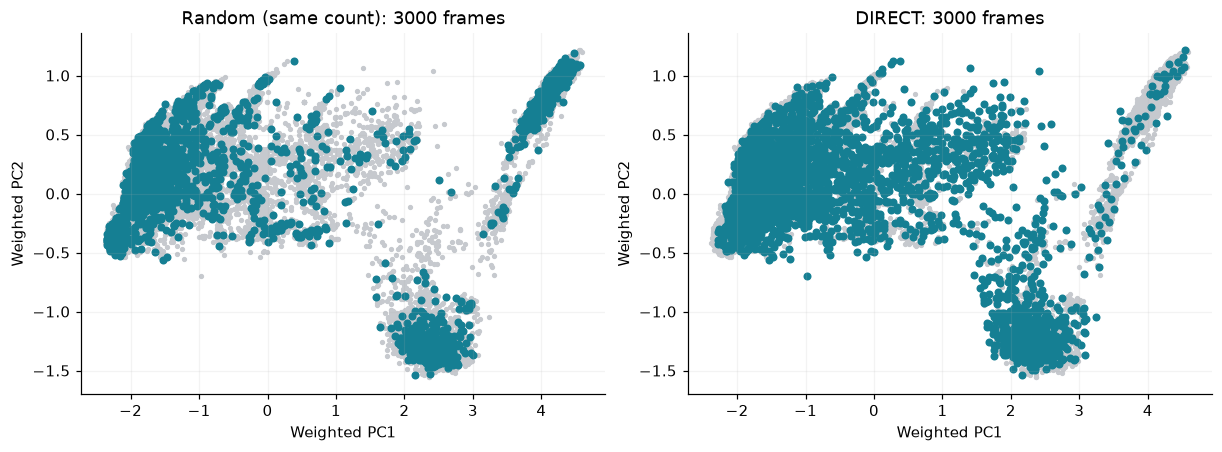

,DIRECT coverage,Random coverage
PC,,
0,1.000,1.000
1,1.000,1.000
2,1.000,0.918
3,1.000,1.000
4,1.000,0.960
5,1.000,0.936
6,1.000,0.900
7,1.000,0.920
8,0.980,0.878


In [2]:
coverage = t.cold_start(scope='full')
display(coverage.round(3))


**图 4｜同数量的随机选择与 DIRECT。** 灰点为练习池，彩色点为选中结构；两图共用同一个 PCA 空间。下表逐个主成分报告覆盖率。来源：当前 DP-EVA 对全量论文特征的实际采样。

In [3]:
def change_budget(n_clusters, scope):
    scores = t.cold_start(n_clusters, scope)
    display(scores.mean().rename('各 PC 覆盖率的均值（教学诊断）').to_frame())
widgets.interact_manual.options(manual_name='运行采样')(change_budget,
    n_clusters=widgets.SelectionSlider(options=[48, 300, 1000, 3000], value=3000, description='聚类数', continuous_update=False),
    scope=widgets.Dropdown(options=[('全量 30,656 帧','full'), ('小切片 768 帧','small')], value='full', description='数据范围'));


## 怎样读覆盖率？
项目实现将每个保留主成分的范围划为 50 个区间，统计所选点占据了多少个原数据占据的区间，再对主成分取平均。这衡量的是特征空间各方向的覆盖；模型精度还需训练后的误差评估。

**本案例的覆盖优势在补充核查中保持。** 在同一 PCA 空间、相同 3,000 点预算下，当前 DIRECT 平均覆盖率为 **98.3%**，历史名单为 **98.5%**；20 个随机种子的平均值为 **89.7%**，范围为 **88.1%–92.2%**。两份 DIRECT 名单均高于这 20 次随机选择，说明名单发生变化后，充分覆盖的结论仍成立。

以上数字来自随教程保存的 [补充核查结果](data/conclusion_audit.json)，并非上方单个随机种子的输出；可用 `python scripts/assess_conclusions.py` 重算。正文按讲解需要舍入，原始计算精度保留。二维图显示前两个保留主成分，其他方向的覆盖可结合表格查看。

**练习**：在全量数据上把预算从 300 调到 3,000，点击“运行采样”。哪些区域最先得到覆盖？增加预算的边际收益是否一直相同？


## 回到论文的冷启动结果
论文 Table 1 将选数方法与训练后的精度联系起来：三种 3,000 帧选择都使用 DPA3 微调，SOAP 在这里指选择结构时采用的特征。

下表展示原论文实验的报告值。各策略在采样后的剩余结构上评估，Full 行为全量参考；阅读时结合这一评估口径。现场计算覆盖与选数，表中精度来自原实验训练。


,strategy,feature,train_frames,energy_rmse_mev_atom,force_mae_ev_A,force_rmse_ev_A
0,Random,NaN,3000,8.16,0.0711,0.9578
1,DIRECT,SOAP,3000,7.40,0.0747,0.1253
2,DIRECT,DPA3,3000,6.08,0.0719,0.1083
3,Full,NaN,30656,5.58,0.0552,0.0822


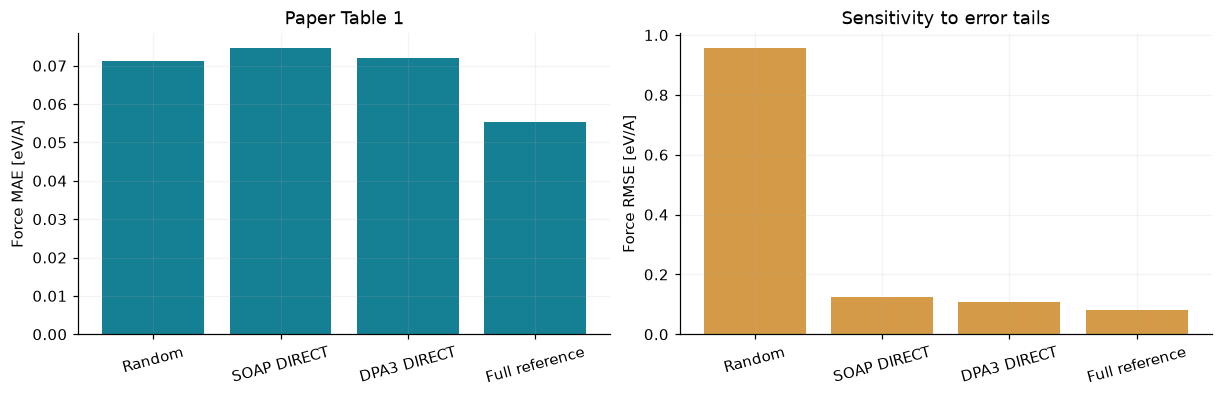

In [4]:
metrics = pd.read_csv(TUTORIAL / 'data/paper_metrics.csv')
cold = metrics.query("stage == 'cold_start'")
display(cold[['strategy','feature','train_frames','energy_rmse_mev_atom','force_mae_ev_A','force_rmse_ev_A']])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
labels = ['Random', 'SOAP DIRECT', 'DPA3 DIRECT', 'Full reference']
axes[0].bar(labels, cold.force_mae_ev_A, color='#157f93')
axes[1].bar(labels, cold.force_rmse_ev_A, color='#d49a47')
axes[0].set(ylabel='Force MAE [eV/A]', title='Paper Table 1')
axes[1].set(ylabel='Force RMSE [eV/A]', title='Sensitivity to error tails')
for ax in axes: ax.tick_params(axis='x', labelrotation=15)
plt.show()


**图 5｜论文冷启动的力误差。** 左图为 MAE，右图为 RMSE；随机方案的长尾误差使两种指标表现不同。来源：论文 Table 1，由本地 `paper_metrics.csv` 重绘。

随机方案的 MAE 与其他方案接近，RMSE 却很大：论文 SI 将它追溯到少数长尾力误差。这个例子适合说明为什么评估不能只看单一平均指标。

下一节：结构代表性之外，如何识别模型还没学好的区域？
